# 04 — Results: how much accuracy does interpretability cost, and when?

This notebook only **reads** the saved model outputs in `outputs/` (written by notebooks 02 and 03) and turns them into every table and figure. The only model fitted here is the small tree that explains the descriptor groups in Part 4. Run it with *Restart and Run All*.

| Part | Question | Figures | Tables (`outputs/`) |
|---|---|---|---|
| 1 | Scores, thresholds and metrics for every model × feature set | — | `all_results.csv` |
| 2 | Baseline: how far behind are the readable models at each budget? | A, B, C | `main_results.csv` |
| 3 | Refinement 1: does a classification-based descriptor choice help? | D | `refinement1.csv` |
| 4 | Refinement 2: in which kinds of chemicals do the models fail? | E, F | `refinement2_groups.csv`, `refinement2_audit.csv` |
| 5 | Frozen parameters | — | `final_parameters.csv` |
| 6 | Test set, evaluated once | G | `test_results.csv`, `test_refinement2_audit.csv` |
| 7 | Summary of findings | — | — |

Labels: **NRB** (not readily biodegradable, y = 1) is the positive class. Development set = 844 chemicals (559 NRB, 285 RB) in 5 stratified folds; test set = 211 chemicals.

## 0. Setup

All switches live in this cell. Only the 7 models in `MODELS_USED` are read; any other files in `outputs/` are ignored.

In [1]:
include("common.jl")
using Printf

MODELS_READ = ["OCT", "OCT-H", "CART", "Logistic"]                  # readable
MODELS_FLEX = ["Random forest", "XGBoost", "Nadaraya-Watson"]        # flexible
MODELS_USED = vcat(MODELS_READ, MODELS_FLEX)

MAIN_SETS  = ["reg_k3", "reg_k5", "reg_k10", "all"]                 # baseline: regression selector + all 41
LOG_SETS   = ["log_k3", "log_k5", "log_k10"]                        # Refinement 1: logistic selector
AUDIT_SETS = ["log_k3", "all"]                                      # sets audited group by group (Part 4)
RUN_TEST   = true
SHOW_ROC   = false

CLUSTER_KS, CLUSTER_RESTARTS = 2:5, 20
PROFILE_DESCRIPTORS = ["SpMax_L", "SM6_B(m)", "SpMax_B(m)", "nHM", "nN", "nO", "C%", "SpPosA_B(p)",
                       "nX", "nCb-", "nCIR", "nArNO2", "LOC", "Me"]

DISPLAY_NAME = Dict("Nadaraya-Watson" => "Kernel regression (Nadaraya-Watson)")
dname(m) = get(DISPLAY_NAME, m, m)
btitle(s) = s == "all" ? "all 41" : (set_sel(s) == "reg" ? "k = $(set_k(s))" : "k = $(set_k(s)), logistic sel.")
f3(x) = @sprintf("%.3f", x)

# slide-readable defaults on top of the common.jl style
default(titlefontsize = 12, guidefontsize = 11, tickfontsize = 10, legendfontsize = 10, grid = false)

common.jl loaded: 7 feature sets, outputs in 'outputs', figures in 'figures'.


---
## Part 1 — Load outputs and compute every metric

For each of the 7 models and 7 feature sets we read the out-of-fold scores (one per development chemical, from a model that never saw that chemical's fold) and the test scores. The fold column of every file must match `outputs/folds.csv`.

In [2]:
D = load_data()
X_dev, y_dev, X_te, y_te = D.X_dev, D.y_dev, D.X_te, D.y_te
fold = load_folds()
fold_feats, final_feats = load_feature_sets()
N_NRB, N_RB = sum(y_dev), length(y_dev) - sum(y_dev)
@assert length(fold) == length(y_dev) && (N_NRB, N_RB) == (559, 285)

read_model(prefix, m) = CSV.read(joinpath(OUT_DIR, "$(prefix)_$(model_tag(m)).csv"), DataFrame)

cvs  = DataFrame()
OOF  = Dict{Tuple{String,String},Vector{Float64}}()
TEST = Dict{Tuple{String,String},Vector{Float64}}()
for m in MODELS_USED
    c = read_model("cv", m)
    c.set, c.model, c.settings = String.(c.set), String.(c.model), String.(string.(c.settings))
    @assert all(c.model .== m) "cv_$(model_tag(m)).csv contains another model name"
    append!(cvs, select(c, :set, :model, :settings, :leaves, :descriptors_used, :max_per_split, :cv_auc); cols = :union)

    o = read_model("oof", m); o.set = String.(o.set)
    for g in groupby(o, :set)
        d = sort(g, :dev_row)
        @assert d.dev_row == 1:length(y_dev) "$m / $(d.set[1]): wrong dev rows"
        @assert d.fold == fold "$m / $(d.set[1]) was not run on the folds in outputs/folds.csv"
        OOF[(String(d.set[1]), m)] = Float64.(d.score)
    end
    t = read_model("test", m); t.set = String.(t.set)
    for g in groupby(t, :set)
        d = sort(g, :test_row)
        @assert d.test_row == 1:length(y_te)
        TEST[(String(d.set[1]), m)] = Float64.(d.score)
    end
end
missing_runs = [(s, m) for s in SETS, m in MODELS_USED if !haskey(OOF, (s, m)) || !haskey(TEST, (s, m))]
@assert isempty(missing_runs) "Missing outputs: $missing_runs"
println("Loaded $(length(MODELS_USED)) models × $(length(SETS)) feature sets; all fold assignments match folds.csv.")

Loaded 7 models × 7 feature sets; all fold assignments match folds.csv.


**Thresholds and metrics.** Both thresholds are chosen on the out-of-fold scores, the same way for every model:
*balanced* maximizes balanced accuracy (average of the share of NRB caught and the share of RB cleared); *NRB-first* is the highest threshold that still catches at least 90% of NRB. **RB cleared** = biodegradable chemicals correctly let through (of 285), i.e. unnecessary lab tests avoided.

In [3]:
fold_aucs(p) = [auc(p[fold .== f], y_dev[fold .== f]) for f in 1:N_FOLDS]

res = DataFrame(set = String[], model = String[], group = String[], settings = String[],
                leaves = Union{Int,Missing}[], descriptors_used = Union{Int,Missing}[],
                cv_auc = Float64[], cv_auc_sd = Float64[],
                thr_bal = Float64[], bal_acc = Float64[], nrb_caught = Int[], rb_cleared_bal = Int[],
                thr_nrbfirst = Float64[], nrb_caught_nrbfirst = Int[], rb_cleared_nrbfirst = Int[])
for s in SETS, m in MODELS_USED
    r  = cvs[(cvs.set .== s) .& (cvs.model .== m), :][1, :]
    p  = OOF[(s, m)]
    fa = fold_aucs(p)
    tb = best_threshold(p, y_dev);                      mb = metrics(p, y_dev; t = tb)
    tn = recall_threshold(p, y_dev, NRB_RECALL_TARGET); mn = metrics(p, y_dev; t = tn)
    push!(res, (s, m, m in MODELS_FLEX ? "flexible" : "readable", r.settings, r.leaves, r.descriptors_used,
                mean(fa), std(fa), tb, mb.bal_acc, N_NRB - mb.nrb_missed, mb.rb_cleared,
                tn, N_NRB - mn.nrb_missed, mn.rb_cleared))
end
has(s, m) = any((res.set .== s) .& (res.model .== m))
row(s, m) = res[(res.set .== s) .& (res.model .== m), :][1, :]

# The model notebooks computed CV AUC the same way; report any difference instead of hiding it.
dmax = maximum(abs(row(r.set, r.model).cv_auc - r.cv_auc) for r in eachrow(cvs) if r.model in MODELS_USED)
println("Largest difference between recomputed CV AUC and the model notebooks' value: ", @sprintf("%.1e", dmax))

with_names(df) = (d = copy(df); d.model = dname.(d.model); d)
CSV.write(joinpath(OUT_DIR, "all_results.csv"), with_names(res))
println("Saved outputs/all_results.csv ($(nrow(res)) rows: model × feature set)")

Largest difference between recomputed CV AUC and the model notebooks' value: 3.4e-02
Saved outputs/all_results.csv (49 rows: model × feature set)


---
## Part 2 — Baseline: readable vs. flexible models at each descriptor budget

Descriptors chosen by the regression selector inside each training fold (k = 3, 5, 10), plus all 41.

### Main results table
Rows are models, columns are budgets. **AUC** measures how well a model ranks NRB above RB (1 = perfect, 0.5 = random); **balanced accuracy** is measured at each model's balanced threshold. Differences smaller than the fold-to-fold spread (`cv_auc_sd` in `all_results.csv`) are not reliable.

In [4]:
main_tbl = DataFrame(model = dname.(MODELS_USED), group = [row("all", m).group for m in MODELS_USED])
for s in MAIN_SETS
    main_tbl[!, "AUC $(btitle(s))"] = [round(row(s, m).cv_auc, digits = 3) for m in MODELS_USED]
end
for s in MAIN_SETS
    main_tbl[!, "BalAcc $(btitle(s))"] = [round(row(s, m).bal_acc, digits = 3) for m in MODELS_USED]
end
CSV.write(joinpath(OUT_DIR, "main_results.csv"), main_tbl)
show(main_tbl, allcols = true, eltypes = false, summary = false)
println("\n\nSaved outputs/main_results.csv")

 Row │ model                              group     AUC k = 3  AUC k = 5  AUC k = 10  AUC all 41  BalAcc k = 3  BalAcc k = 5  BalAcc k = 10  BalAcc all 41 
─────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ OCT                                readable      0.823      0.845       0.805       0.824         0.788         0.816          0.77           0.798
   2 │ OCT-H                              readable      0.829      0.848       0.838       0.856         0.792         0.81           0.825          0.846
   3 │ CART                               readable      0.835      0.828       0.822       0.833         0.795         0.79           0.769          0.801
   4 │ Logistic                           readable      0.852      0.869       0.898       0.931         0.788         0.804          0.823          0.868
   5 │ Random forest                      flexible      0.878      0

**Plot helper.** Dot plots have the models as rows: the 4 readable models on top (filled, in their own colors), the 3 flexible models below (hollow, gray), separated by a thin line. One panel per budget, same x-axis in every panel.

In [5]:
PLOT_ORDER = MODELS_USED
nP, nR = length(PLOT_ORDER), length(MODELS_READ)
YPOS = Dict(m => nP - i + 1 for (i, m) in enumerate(PLOT_ORDER))      # first model at the top
YLABELS = reverse(dname.(PLOT_ORDER))
panel_widths(n; first = 2.1) = (w = vcat(first, ones(n - 1)); w ./ sum(w))   # first panel also holds the row labels

function shared_xlims(vals; pad = 0.08, step = nothing)
    lo, hi = extrema(filter(!isnan, collect(vals))); d = max(hi - lo, eps())
    lo, hi = lo - pad * d, hi + pad * d
    step === nothing ? (lo, hi) : (floor(lo / step) * step, ceil(hi / step) * step)
end

# One row of dot-plot panels: value(s, m) gives the x-position of model m in panel s.
function dotplot(value, sets; xlabel = "", title = "", xlims = nothing, models = PLOT_ORDER, height = 70 + 42length(models))
    n = length(sets)
    xl = xlims === nothing ? shared_xlims([value(s, m) for s in sets for m in models]) : xlims
    ys = Dict(m => length(models) - i + 1 for (i, m) in enumerate(models))
    nread = count(in(MODELS_READ), models)
    fig = plot(layout = grid(1, n; widths = panel_widths(n)), size = (290n + 230, height), legend = false,
               bottom_margin = 5Plots.mm, top_margin = 2Plots.mm)
    for (j, s) in enumerate(sets)
        nread < length(models) && hline!(fig, [length(models) - nread + 0.5]; subplot = j, color = :gray75, lw = 0.8)
        for m in models
            scatter!(fig, [value(s, m)], [ys[m]]; subplot = j, ms = 8, mkw(m)...)
        end
        plot!(fig; subplot = j, title = btitle(s), xlims = xl, ylims = (0.4, length(models) + 0.6),
              yticks = (1:length(models), j == 1 ? reverse(dname.(models)) : fill("", length(models))),
              xlabel = xlabel, grid = :x, gridalpha = 0.12, xguidefontsize = 10)
    end
    isempty(title) || plot!(fig; plot_title = title, plot_titlefontsize = 13)
    fig
end

dotplot (generic function with 1 method)

### Figure A — Ranking quality (CV AUC) at each budget
Further right is better. The horizontal distance between the best filled dot and the best hollow dot in a panel is the price of readability at that budget.




In [6]:
figA = dotplot((s, m) -> row(s, m).cv_auc, MAIN_SETS; xlabel = "Mean 5-fold CV AUC",
               title = "Ranking quality by descriptor budget")
savefig_(figA, "04_A_auc_by_budget.png")

### Figure B — Unnecessary lab tests avoided (NRB-first threshold)
Each model's threshold is set so it catches at least 90% of NRB chemicals. The x-axis counts RB chemicals (of 285) that are still correctly cleared at that threshold; further right means fewer unnecessary tests for the same safety level.

In [7]:
println("RB cleared (of $N_RB) at the NRB-first threshold (≥ $(round(Int, 100NRB_RECALL_TARGET))% of NRB caught)")
tblB = DataFrame(model = dname.(MODELS_USED))
for s in MAIN_SETS
    tblB[!, btitle(s)] = [row(s, m).rb_cleared_nrbfirst for m in MODELS_USED]
end
show(tblB, eltypes = false, summary = false); println()

RB cleared (of 285) at the NRB-first threshold (≥ 90% of NRB caught)
 Row │ model                              k = 3  k = 5  k = 10  all 41 
─────┼─────────────────────────────────────────────────────────────────
   1 │ OCT                                  152    196     167     180
   2 │ OCT-H                                150    194     210     214
   3 │ CART                                 150    151     169     184
   4 │ Logistic                             169    168     211     226
   5 │ Random forest                        183    216     216     235
   6 │ XGBoost                              189    204     218     229
   7 │ Kernel regression (Nadaraya-Wats…    178    208     216     222





In [8]:
figB = dotplot((s, m) -> row(s, m).rb_cleared_nrbfirst, MAIN_SETS;
               xlabel = "RB cleared (of $N_RB) at ≥ 90% NRB caught", title = "Unnecessary lab tests avoided")
savefig_(figB, "04_B_rb_cleared_nrb_first.png")

### Figure C — Tree depth trade-off
Cross-validated AUC of each tree type as its maximum depth grows (from the tuning runs in notebook 02). The dotted line is the best flexible model at the same budget, labeled with its name. If a tree's curve flattens below that line, more depth only makes the tree harder to read without closing the gap.




In [9]:
TREES = ["OCT", "CART", "OCT-H"]
depths = vcat([read_model("depth", m) for m in TREES]...)
depths.set, depths.model = String.(depths.set), String.(depths.model)
best_flex(s) = (i = argmax([row(s, m).cv_auc for m in MODELS_FLEX]); MODELS_FLEX[i])

dsub = filter(r -> r.set in MAIN_SETS, depths)
ylo, yhi = shared_xlims(vcat(dsub.cv_auc, [row(s, best_flex(s)).cv_auc for s in MAIN_SETS]); pad = 0.12)
nS = length(MAIN_SETS)
figC = plot(layout = (1, nS), size = (330nS, 380), xticks = sort(unique(dsub.max_depth)), ylims = (ylo, yhi),
            legend = :bottomright, bottom_margin = 6Plots.mm, left_margin = 4Plots.mm)
for (j, s) in enumerate(MAIN_SETS)
    bf = best_flex(s); fv = row(s, bf).cv_auc
    hline!(figC, [fv]; subplot = j, color = GRAY, ls = :dot, lw = 2, label = "")
    plot!(figC; subplot = j, annotations = (minimum(dsub.max_depth), fv + 0.004, text(dname(bf), 9, :gray40, :left, :bottom)))
    for m in TREES
        d = sort(filter(r -> r.set == s && r.model == m, dsub), :max_depth)
        plot!(figC, d.max_depth, d.cv_auc; subplot = j, lw = 2, ms = 5, mkw(m)..., label = j == 1 ? m : "")
    end
    plot!(figC; subplot = j, title = btitle(s), xlabel = "Maximum depth", ylabel = j == 1 ? "Mean 5-fold CV AUC" : "",
          grid = :y, gridalpha = 0.12, legend = j == 1 ? :bottomright : false)
end
plot!(figC; plot_title = "Tree depth trade-off (dotted: best flexible model)", plot_titlefontsize = 13)
savefig_(figC, "04_C_depth_tradeoff.png")

---
## Part 3 — Refinement 1: choosing descriptors with a classification objective

Same models and tuning; the only difference is which descriptors they get at each budget: the **regression selector** (best-subset least squares, baseline) or the **logistic selector** (sparse logistic regression, Ch. 6 §6.2–6.3). Both are run inside each training fold.

### Descriptor lists and their stability
The final lists (fold 0, chosen on all 844 chemicals) and how stable each selector was across the 5 training folds. `mean_jaccard` is the average overlap between the fold lists (1 = identical every time).

In [10]:
for k in KS, sel in SELECTORS
    s = "$(sel)_k$k"
    println(rpad("$(btitle("reg_k$k")) | $(SEL_NAME[sel]):", 42), join(final_feats[s], ", "))
end
stab = CSV.read(joinpath(OUT_DIR, "selection_stability.csv"), DataFrame)
println()
show(select(stab, :k, :selector, :mean_jaccard, :always_chosen), eltypes = false, summary = false)
println()

k = 3 | regression selector:              SpMax_L, LOC, SpPosA_B(p)
k = 3 | logistic selector:                SpMax_L, nHM, nN
k = 5 | regression selector:              SpMax_L, nO, LOC, nN, SM6_B(m)
k = 5 | logistic selector:                SpMax_L, nHM, nO, nN, SM6_B(m)
k = 10 | regression selector:             SpMax_L, C%, nO, HyWi_B(m), LOC, F03[C-O], nArNO2, SpPosA_B(p), nN, nArCOOR
k = 10 | logistic selector:               SpMax_L, nHM, NssssC, nO, LOC, nArNO2, Psi_i_A, nN, SM6_B(m), nArCOOR

 Row │ k   selector             mean_jaccard  always_chosen                  
─────┼───────────────────────────────────────────────────────────────────────
   1 │  3  regression selector          0.48  SpMax_L
   2 │  3  logistic selector            0.68  SpMax_L
   3 │  5  regression selector          0.43  SpMax_L
   4 │  5  logistic selector            0.6   SpMax_L
   5 │ 10  regression selector          0.52  SpMax_L, HyWi_B(m), LOC
   6 │ 10  logistic selector            0.62  SpMax_L,

### Refinement 1 table
For every model and budget: the regression-selector value, the logistic-selector value, and the difference (logistic − regression). A positive `Δ` in AUC, balanced accuracy or RB cleared means the logistic selector helped; a negative `Δ` in leaves means a smaller tree.

In [11]:
ref1 = DataFrame(model = String[], k = Int[],
                 auc_reg = Float64[], auc_log = Float64[], Δ_auc = Float64[],
                 balacc_reg = Float64[], balacc_log = Float64[], Δ_balacc = Float64[],
                 rbcleared_reg = Int[], rbcleared_log = Int[], Δ_rbcleared = Int[],
                 leaves_reg = Union{Int,Missing}[], leaves_log = Union{Int,Missing}[], Δ_leaves = Union{Int,Missing}[])
for m in MODELS_USED, k in KS
    a, b = row("reg_k$k", m), row("log_k$k", m)
    push!(ref1, (dname(m), k, round(a.cv_auc, digits = 3), round(b.cv_auc, digits = 3), round(b.cv_auc - a.cv_auc, digits = 3),
                 round(a.bal_acc, digits = 3), round(b.bal_acc, digits = 3), round(b.bal_acc - a.bal_acc, digits = 3),
                 a.rb_cleared_nrbfirst, b.rb_cleared_nrbfirst, b.rb_cleared_nrbfirst - a.rb_cleared_nrbfirst,
                 a.leaves, b.leaves, b.leaves - a.leaves))
end
CSV.write(joinpath(OUT_DIR, "refinement1.csv"), ref1)
show(ref1, allrows = true, allcols = true, eltypes = false, summary = false)
println("\n\nSaved outputs/refinement1.csv")

 Row │ model                              k   auc_reg  auc_log  Δ_auc   balacc_reg  balacc_log  Δ_balacc  rbcleared_reg  rbcleared_log  Δ_rbcleared  leaves_reg  leaves_log  Δ_leaves 
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ OCT                                 3    0.823    0.844   0.021       0.788       0.798     0.01             152            180           28           9           6        -3
   2 │ OCT                                 5    0.845    0.83   -0.016       0.816       0.802    -0.014            196            138          -58           9           8        -1
   3 │ OCT                                10    0.805    0.826   0.022       0.77        0.799     0.029            167            183           16           8          12         4
   4 │ OCT-H                               3    0.829    0.821  -0.009       0.792      

### Figure D — Regression vs. logistic selector for the readable models
Hollow marker = regression selector, filled marker = logistic selector, joined by a thin line. A filled marker to the right of its hollow partner means the classification-based choice of descriptors helped that model.

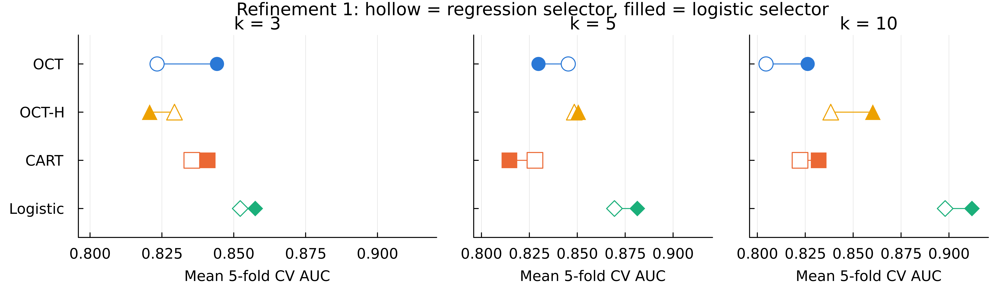

In [12]:
r1vals = [row(sel * "_k$k", m).cv_auc for k in KS, m in MODELS_READ, sel in SELECTORS]
xlD = shared_xlims(vec(r1vals))
nM = length(MODELS_READ)
figD = plot(layout = grid(1, length(KS); widths = panel_widths(length(KS); first = 1.5)), size = (300length(KS) + 120, 90 + 50nM),
            legend = false, bottom_margin = 5Plots.mm)
for (j, k) in enumerate(KS)
    for (i, m) in enumerate(MODELS_READ)
        y = nM - i + 1
        a, b = row("reg_k$k", m).cv_auc, row("log_k$k", m).cv_auc
        plot!(figD, [a, b], [y, y]; subplot = j, color = STYLE[m].color, lw = 1)
        scatter!(figD, [a], [y]; subplot = j, ms = 8, markershape = STYLE[m].marker, markercolor = :white,
                 markerstrokecolor = STYLE[m].color, markerstrokewidth = 1.8)
        scatter!(figD, [b], [y]; subplot = j, ms = 8, markershape = STYLE[m].marker, markercolor = STYLE[m].color,
                 markerstrokecolor = STYLE[m].color)
    end
    plot!(figD; subplot = j, title = "k = $k", xlims = xlD, ylims = (0.4, nM + 0.6),
          yticks = (1:nM, j == 1 ? reverse(MODELS_READ) : fill("", nM)), xlabel = "Mean 5-fold CV AUC",
          grid = :x, gridalpha = 0.12, xguidefontsize = 10)
end
plot!(figD; plot_title = "Refinement 1: hollow = regression selector, filled = logistic selector", plot_titlefontsize = 12)
savefig_(figD, "04_D_refinement1_selectors.png")

---
## Part 4 — Refinement 2: in which kinds of chemicals do the models fail?

Following Ch. 20 §20.2: group the development chemicals **by their descriptors only** (no labels), explain the groups with a shallow tree, and then check every model's out-of-fold mistakes group by group.

Steps: (1) convert each descriptor to its percentile among the 844 development chemicals, so a few extreme values cannot dominate; (2) run k-means (k-means++ starts, several restarts) for K = 2 to 5; (3) choose K by the mean silhouette (how much closer each chemical is to its own group than to the next one; near 0 means weakly separated groups).

**4a. Percentile scaling.** Test chemicals are scaled with the development percentiles, so nothing about the test set is used.

In [13]:
DEV_SORTED = [sort(Float64.(X_dev[!, c])) for c in DESCRIPTORS]

function percentile_scale(X)
    n, p = nrow(X), length(DESCRIPTORS)
    P = zeros(n, p)
    for (c, name) in enumerate(DESCRIPTORS)
        ref, nref = DEV_SORTED[c], length(DEV_SORTED[c])
        col = Float64.(X[!, name])
        for i in 1:n
            lo, hi = searchsortedfirst(ref, col[i]), searchsortedlast(ref, col[i])
            P[i, c] = (lo - 1 + 0.5 * (hi - lo + 1)) / nref          # ties share the middle rank
        end
    end
    P
end
P_dev = percentile_scale(X_dev)
println("Percentile matrix: ", size(P_dev))

Percentile matrix: (844, 41)


**4b. Distance matrix**, computed once (844 × 844) and reused for every silhouette.

In [14]:
function distance_matrix(P)
    n, p = size(P)
    Dm = zeros(n, n)
    for i in 1:n, j in (i + 1):n
        acc = 0.0
        for c in 1:p
            acc += (P[i, c] - P[j, c])^2
        end
        Dm[i, j] = Dm[j, i] = sqrt(acc)
    end
    Dm
end
DIST = distance_matrix(P_dev)
println("Distance matrix: ", size(DIST), ", ", round(sizeof(DIST) / 2^20, digits = 1), " MB")

Distance matrix: (844, 844), 5.4 MB


**4c. k-means with k-means++ starts.** Plain loops; the best of `CLUSTER_RESTARTS` runs (lowest within-group sum of squares) is kept. Groups are numbered by size (G1 = largest).

In [15]:
function sqdist(P, i, C, j)                            # squared distance between row i of P and row j of C
    acc = 0.0
    for c in axes(P, 2)
        acc += (P[i, c] - C[j, c])^2
    end
    acc
end

function kmeans_once(P, K, rng; iters = 100)
    n, p = size(P)
    C = zeros(K, p)
    C[1, :] = P[rand(rng, 1:n), :]
    d2 = [sqdist(P, i, C, 1) for i in 1:n]
    for j in 2:K                                       # k-means++: new centre drawn proportional to squared distance
        target, acc, pick = rand(rng) * sum(d2), 0.0, n
        for i in 1:n
            acc += d2[i]
            if acc >= target
                pick = i; break
            end
        end
        C[j, :] = P[pick, :]
        for i in 1:n
            d2[i] = min(d2[i], sqdist(P, i, C, j))
        end
    end
    a = zeros(Int, n)
    for _ in 1:iters
        changed = false
        for i in 1:n
            best_j, best_d = 1, Inf
            for j in 1:K
                d = sqdist(P, i, C, j)
                d < best_d && ((best_j, best_d) = (j, d))
            end
            if a[i] != best_j
                a[i] = best_j; changed = true
            end
        end
        for j in 1:K
            members = findall(==(j), a)
            isempty(members) || (C[j, :] = vec(mean(P[members, :], dims = 1)))
        end
        changed || break
    end
    a, C, sum(sqdist(P, i, C, a[i]) for i in 1:n)
end

function kmeans_pp(P, K; restarts = CLUSTER_RESTARTS, seed = SEED)
    rng = MersenneTwister(seed)
    best_a, best_C, best_cost = kmeans_once(P, K, rng)
    for _ in 2:restarts
        a, C, cost = kmeans_once(P, K, rng)
        cost < best_cost && ((best_a, best_C, best_cost) = (a, C, cost))
    end
    ord = sortperm([count(==(j), best_a) for j in 1:K], rev = true)
    (assign = invperm(ord)[best_a], centers = best_C[ord, :], cost = best_cost)
end

function mean_silhouette(a, Dm)
    n, K = length(a), maximum(a)
    s = zeros(n)
    for i in 1:n
        sums, cnt = zeros(K), zeros(Int, K)
        for j in 1:n
            j == i && continue
            sums[a[j]] += Dm[i, j]; cnt[a[j]] += 1
        end
        cnt[a[i]] == 0 && continue
        ai = sums[a[i]] / cnt[a[i]]
        bi = minimum(sums[k] / cnt[k] for k in 1:K if k != a[i] && cnt[k] > 0)
        s[i] = (bi - ai) / max(ai, bi)
    end
    mean(s)
end

mean_silhouette (generic function with 1 method)

In [16]:
clust = Dict(K => kmeans_pp(P_dev, K) for K in CLUSTER_KS)
sil = DataFrame(K = collect(CLUSTER_KS), silhouette = [round(mean_silhouette(clust[K].assign, DIST), digits = 3) for K in CLUSTER_KS])
K_BEST = sil.K[argmax(sil.silhouette)]
cl_dev = clust[K_BEST].assign
GROUPS = ["G$j" for j in 1:K_BEST]
show(sil, eltypes = false, summary = false)
println("\nChosen number of groups: K = $K_BEST")

 Row │ K  silhouette 
─────┼───────────────
   1 │ 2       0.179
   2 │ 3       0.154
   3 │ 4       0.147
   4 │ 5       0.139
Chosen number of groups: K = 2


### Group profiles and Figure E
The table gives each group's size, share of NRB, and the median raw value of key descriptors. The heatmap shows the same medians as percentiles (red = high relative to all development chemicals, blue = low), so groups can be named by their properties (size/branching, heavy atoms, nitrogen, …).

In [17]:
prof = DataFrame(group = GROUPS, n = [count(==(j), cl_dev) for j in 1:K_BEST],
                 share_NRB = [round(mean(y_dev[cl_dev .== j]), digits = 2) for j in 1:K_BEST])
for c in PROFILE_DESCRIPTORS
    prof[!, c] = [median(Float64.(X_dev[cl_dev .== j, c])) for j in 1:K_BEST]
end
CSV.write(joinpath(OUT_DIR, "refinement2_groups.csv"), prof)
show(prof, allcols = true, eltypes = false, summary = false)
println("\n\nSaved outputs/refinement2_groups.csv")

 Row │ group  n    share_NRB  SpMax_L  SM6_B(m)  SpMax_B(m)  nHM  nN   nO   C%    SpPosA_B(p)  nX   nCb-  nCIR  nArNO2  LOC     Me    
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ G1     438       0.85   5.0395    8.9135      3.9215  0.0  0.0  2.0  42.1       1.277   0.0   3.0   2.0     0.0  1.0505  1.015
   2 │ G2     406       0.46   4.473     7.991       3.4775  0.0  0.0  1.0  31.6       1.1975  0.0   0.0   0.0     0.0  1.459   0.993

Saved outputs/refinement2_groups.csv


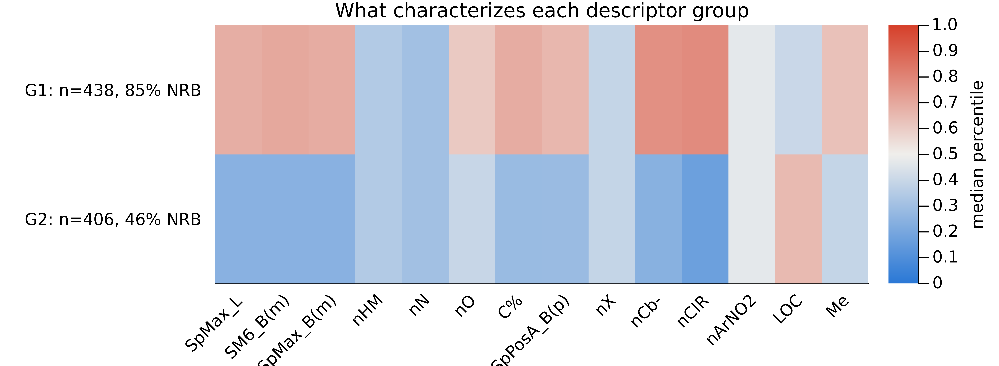

In [18]:
pidx = [findfirst(==(c), DESCRIPTORS) for c in PROFILE_DESCRIPTORS]
med_pct = [median(P_dev[cl_dev .== j, i]) for j in 1:K_BEST, i in pidx]
glabels = ["$(GROUPS[j]): n=$(prof.n[j]), $(round(Int, 100prof.share_NRB[j]))% NRB" for j in 1:K_BEST]
figE = heatmap(PROFILE_DESCRIPTORS, glabels, med_pct; c = cgrad([NEG_COLOR, MID_COLOR, POS_COLOR]), clims = (0, 1),
               yflip = true, xrotation = 45, size = (900, 220 + 55K_BEST), colorbar_title = "median percentile",
               title = "What characterizes each descriptor group", bottom_margin = 8Plots.mm, left_margin = 4Plots.mm)
savefig_(figE, "04_E_group_profiles.png")

### A shallow tree that explains the groups
An OCT of depth 1–3 (depth chosen on fold 1 as validation) is trained to predict each chemical's group from its raw descriptors. If it agrees closely with k-means, the groups can be described by a few readable rules.

In [19]:
cl_labels = GROUPS[cl_dev]
vg = fold .== 1
cgrid = IAI.GridSearch(IAI.OptimalTreeClassifier(random_seed = SEED, minbucket = 20), max_depth = 1:3)
IAI.fit!(cgrid, X_dev[.!vg, :], cl_labels[.!vg], X_dev[vg, :], cl_labels[vg], validation_criterion = :misclassification)
bp = IAI.get_best_params(cgrid)
tree_kw = haskey(bp, :cp) ? (max_depth = bp[:max_depth], cp = bp[:cp]) : (max_depth = bp[:max_depth],)
group_tree = IAI.OptimalTreeClassifier(; random_seed = SEED, minbucket = 20, tree_kw...)
IAI.fit!(group_tree, X_dev, cl_labels)
agree = mean(IAI.predict(group_tree, X_dev) .== cl_labels)
println("Group tree: max_depth = $(bp[:max_depth]); agreement with k-means = $(round(100agree, digits = 1))%\n")
println(group_tree)
mkpath(joinpath(FIG_DIR, "trees"))
IAI.write_html(joinpath(FIG_DIR, "trees", "04_group_tree.html"), group_tree)

[ Warning: This copy of Interpretable AI software is for academic purposes only and not for commercial use.


Group tree: max_depth = 3; agreement with k-means = 96.2%

Fitted OptimalTreeClassifier:
  1) Split: SM6_B(m) < 8.231
    2) Predict: G2 (97.43%), [8,303], 311 points, error 0.02572
    3) Split: Mi < 1.14
      4) Split: SpMax_A < 2.168
        5) Predict: G2 (95.83%), [2,46], 48 points, error 0.04167
        6) Predict: G1 (96.63%), [402,14], 416 points, error 0.03365
      7) Split: SpMax_A < 2.295
        8) Predict: G2 (94.87%), [2,37], 39 points, error 0.05128
        9) Predict: G1 (80.00%), [24,6], 30 points, error 0.2


636390

### Error audit per group and Figure F
For each audited feature set, every model's out-of-fold results within each group, at the model's own frozen thresholds: balanced accuracy, % of NRB missed and % of RB cleared (balanced threshold), and % of RB cleared at the NRB-first threshold. `small = true` flags groups with fewer than 15 NRB or 15 RB, whose rates are unreliable. In Figure F, a group where every model scores low is a blind spot of the descriptors; a group where only the readable models fall behind is where readability costs most.

In [20]:
audit = DataFrame(set = String[], model = String[], group = String[], n = Int[], NRB = Int[], RB = Int[],
                  bal_acc = Float64[], nrb_missed_pct = Float64[], rb_cleared_pct = Float64[],
                  rb_cleared_nrbfirst_pct = Float64[], small = Bool[])
for s in AUDIT_SETS, m in MODELS_USED, j in 1:K_BEST
    r, idx = row(s, m), cl_dev .== j
    yj, pj = y_dev[idx], OOF[(s, m)][idx]
    mb, mn = metrics(pj, yj; t = r.thr_bal), metrics(pj, yj; t = r.thr_nrbfirst)
    push!(audit, (s, m, GROUPS[j], sum(idx), sum(yj), sum(1 .- yj), round(mb.bal_acc, digits = 3),
                  round(100 * (1 - mb.recall), digits = 1), round(100 * mb.specificity, digits = 1),
                  round(100 * mn.specificity, digits = 1), min(sum(yj), sum(1 .- yj)) < 15))
end
CSV.write(joinpath(OUT_DIR, "refinement2_audit.csv"), with_names(audit))
for s in AUDIT_SETS
    println("=== $(btitle(s)) ===")
    show(select(with_names(filter(r -> r.set == s, audit)), Not(:set)), allrows = true, allcols = true, eltypes = false, summary = false)
    println("\n")
end
println("Saved outputs/refinement2_audit.csv")

=== k = 3, logistic sel. ===
 Row │ model                              group  n    NRB  RB   bal_acc  nrb_missed_pct  rb_cleared_pct  rb_cleared_nrbfirst_pct  small 
─────┼──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ OCT                                G1     438  373   65    0.679             7.2            43.1                     27.7  false
   2 │ OCT                                G2     406  186  220    0.765            31.2            84.1                     73.6  false
   3 │ OCT-H                              G1     438  373   65    0.643             6.7            35.4                     24.6  false
   4 │ OCT-H                              G2     406  186  220    0.786            27.4            84.5                     80.0  false
   5 │ CART                               G1     438  373   65    0.678             7.5            43.1                     15.4  false
   6 │ CART      

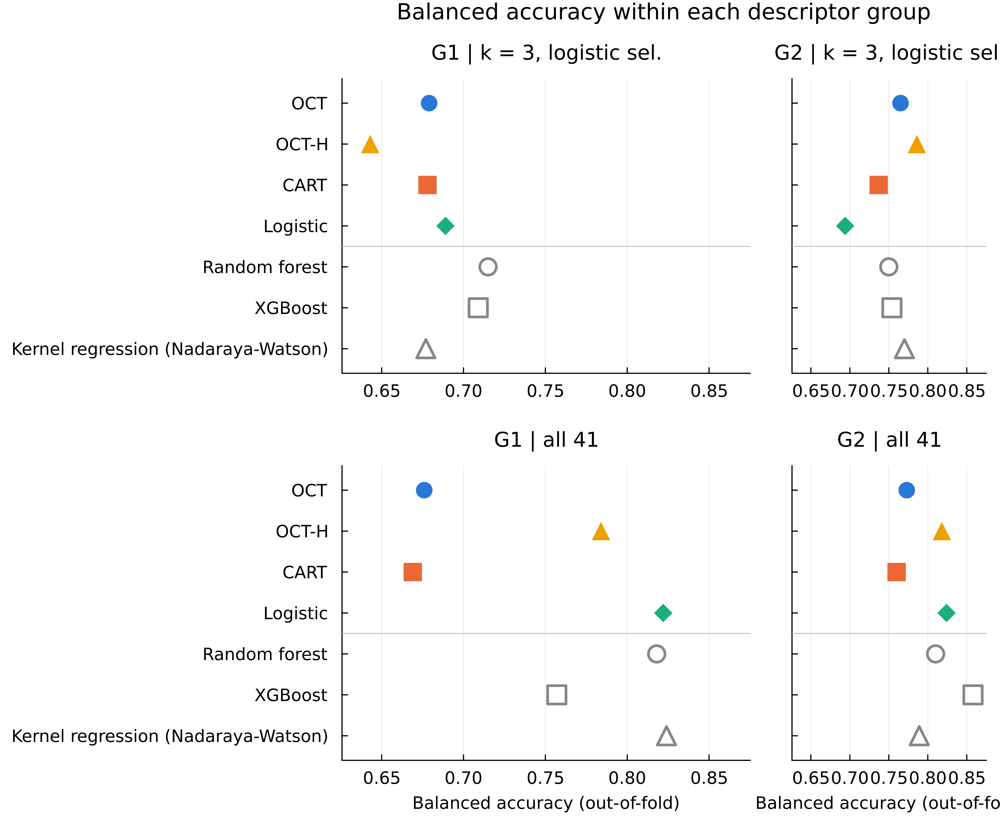

In [21]:
aud(s, m, g) = audit[(audit.set .== s) .& (audit.model .== m) .& (audit.group .== g), :][1, :]
xlF = shared_xlims(audit.bal_acc)
nA = length(AUDIT_SETS)
figF = plot(layout = grid(nA, K_BEST; widths = panel_widths(K_BEST)), size = (320K_BEST + 230, nA * (70 + 42nP)),
            legend = false, bottom_margin = 4Plots.mm)
for (a, s) in enumerate(AUDIT_SETS), j in 1:K_BEST
    sp = (a - 1) * K_BEST + j
    hline!(figF, [nP - nR + 0.5]; subplot = sp, color = :gray75, lw = 0.8)
    for m in PLOT_ORDER
        scatter!(figF, [aud(s, m, GROUPS[j]).bal_acc], [YPOS[m]]; subplot = sp, ms = 8, mkw(m)...)
    end
    plot!(figF; subplot = sp, title = "$(GROUPS[j]) | $(btitle(s))", xlims = xlF, ylims = (0.4, nP + 0.6),
          yticks = (1:nP, j == 1 ? YLABELS : fill("", nP)), xlabel = a == nA ? "Balanced accuracy (out-of-fold)" : "",
          grid = :x, gridalpha = 0.12, xguidefontsize = 10)
end
plot!(figF; plot_title = "Balanced accuracy within each descriptor group", plot_titlefontsize = 13)
savefig_(figF, "04_F_errors_by_group.png")

**Test chemicals** are assigned to the nearest frozen group centre (in percentile space). These assignments are used only in Part 6.

In [22]:
P_te = percentile_scale(X_te)
CENTERS = clust[K_BEST].centers
cl_te = [argmin([sqdist(P_te, i, CENTERS, j) for j in 1:K_BEST]) for i in 1:size(P_te, 1)]
println("Test chemicals per group: ", join(["$(GROUPS[j]) $(count(==(j), cl_te))" for j in 1:K_BEST], ", "))

Test chemicals per group: G1 100, G2 111


---
## Part 5 — Frozen parameters

Everything the test evaluation uses, fixed before looking at the test set: the settings chosen by cross-validation, the final descriptor list (chosen on all 844 chemicals), and both thresholds.

In [23]:
params = select(res, :set, :model, :group, :settings, :leaves, :descriptors_used, :cv_auc, :thr_bal, :thr_nrbfirst)
params.descriptors = [join(final_feats[s], "; ") for s in params.set]
CSV.write(joinpath(OUT_DIR, "final_parameters.csv"), with_names(params))
show(select(with_names(params), :set, :model, :settings, :thr_bal, :thr_nrbfirst), allrows = true, eltypes = false, summary = false)
println("\n\nSaved outputs/final_parameters.csv")

 Row │ set      model                              settings                    ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │ reg_k3   OCT                                max_depth=4, minbucket=20,  ⋯
   2 │ reg_k3   OCT-H                              max_depth=3, minbucket=5, c
   3 │ reg_k3   CART                               max_depth=4, minbucket=20,
   4 │ reg_k3   Logistic                           lambda=0.001
   5 │ reg_k3   Random forest                      max_depth=6, minbucket=1    ⋯
   6 │ reg_k3   XGBoost                            max_depth=2, eta=0.05
   7 │ reg_k3   Kernel regression (Nadaraya-Wats…  g=10.0
   8 │ log_k3   OCT                                max_depth=4, minbucket=20,
   9 │ log_k3   OCT-H                              max_depth=4, minbucket=10,  ⋯
  10 │ log_k3   CART                               max_depth=4, minbucket=20,
  11 │ log_k3   Logistic                           lambda=10.0
  12 │ log_k3   Random f

---
## Part 6 — Test set (evaluated once)

The frozen thresholds from Part 5 are applied to the test scores of the final models (fitted on all 844 development chemicals). Test set: 140 NRB, 71 RB. With only 211 chemicals, test AUC differences of a few hundredths are within noise; the test checks that the cross-validated picture holds, not which model wins.

### Test results table

In [24]:
if RUN_TEST
    T_NRB, T_RB = sum(y_te), length(y_te) - sum(y_te)
    tres = DataFrame(set = String[], model = String[], group = String[], cv_auc = Float64[], test_auc = Float64[],
                     test_bal_acc = Float64[], nrb_caught = Int[], rb_cleared_bal = Int[],
                     nrb_caught_nrbfirst = Int[], rb_cleared_nrbfirst = Int[])
    for r in eachrow(res)
        p = TEST[(r.set, r.model)]
        mb, mn = metrics(p, y_te; t = r.thr_bal), metrics(p, y_te; t = r.thr_nrbfirst)
        push!(tres, (r.set, r.model, r.group, round(r.cv_auc, digits = 3), round(auc(p, y_te), digits = 3),
                     round(mb.bal_acc, digits = 3), T_NRB - mb.nrb_missed, mb.rb_cleared, T_NRB - mn.nrb_missed, mn.rb_cleared))
    end
    trow(s, m) = tres[(tres.set .== s) .& (tres.model .== m), :][1, :]
    CSV.write(joinpath(OUT_DIR, "test_results.csv"), with_names(tres))
    println("Test set: $T_NRB NRB, $T_RB RB. nrb_caught is of $T_NRB; rb_cleared is of $T_RB.\n")
    for s in vcat(MAIN_SETS, LOG_SETS)
        println("=== Test | $(btitle(s)) ===")
        show(select(with_names(filter(r -> r.set == s, tres)), Not([:set, :group])), eltypes = false, summary = false)
        println("\n")
    end
    println("Saved outputs/test_results.csv")
else
    println("Test evaluation is switched off (RUN_TEST = false).")
end

Test set: 140 NRB, 71 RB. nrb_caught is of 140; rb_cleared is of 71.

=== Test | k = 3 ===
 Row │ model                              cv_auc  test_auc  test_bal_acc  nrb_ ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │ OCT                                 0.823     0.731         0.724       ⋯
   2 │ OCT-H                               0.829     0.778         0.705
   3 │ CART                                0.835     0.761         0.748
   4 │ Logistic                            0.852     0.802         0.752
   5 │ Random forest                       0.878     0.808         0.717       ⋯
   6 │ XGBoost                             0.88      0.794         0.727
   7 │ Kernel regression (Nadaraya-Wats…   0.872     0.783         0.741
                                                               4 columns omitted

=== Test | k = 5 ===
 Row │ model                              cv_auc  test_auc  test_bal_acc  nrb_ ⋯
─────┼──────────────────────────────

### Figure G — Test AUC vs. CV AUC
Each model's test AUC (its usual marker) next to its cross-validated AUC (small gray dot), joined by a thin line. Top row: baseline sets; bottom row: logistic-selector sets. Short lines mean the cross-validated estimate held up on new chemicals.

In [25]:
if RUN_TEST
    G_ROWS = [MAIN_SETS, vcat(LOG_SETS, [""])]
    nc = length(MAIN_SETS)
    xlG = shared_xlims(vcat(tres.cv_auc, tres.test_auc))
    figG = plot(layout = grid(2, nc; widths = panel_widths(nc)), size = (290nc + 230, 2 * (70 + 42nP)), legend = false,
                bottom_margin = 4Plots.mm)
    for (a, sets) in enumerate(G_ROWS), (j, s) in enumerate(sets)
        sp = (a - 1) * nc + j
        if s == ""
            plot!(figG; subplot = sp, framestyle = :none, xticks = false, yticks = false)
            continue
        end
        hline!(figG, [nP - nR + 0.5]; subplot = sp, color = :gray75, lw = 0.8)
        for m in PLOT_ORDER
            t = trow(s, m)
            plot!(figG, [t.cv_auc, t.test_auc], [YPOS[m], YPOS[m]]; subplot = sp, color = :gray70, lw = 1)
            scatter!(figG, [t.cv_auc], [YPOS[m]]; subplot = sp, ms = 4, color = :gray60, markerstrokecolor = :gray60)
            scatter!(figG, [t.test_auc], [YPOS[m]]; subplot = sp, ms = 8, mkw(m)...)
        end
        plot!(figG; subplot = sp, title = btitle(s), xlims = xlG, ylims = (0.4, nP + 0.6),
              yticks = (1:nP, j == 1 ? YLABELS : fill("", nP)), xlabel = "AUC", grid = :x, gridalpha = 0.12)
    end
    plot!(figG; plot_title = "Test AUC (marker) vs. CV AUC (small gray dot)", plot_titlefontsize = 13)
    savefig_(figG, "04_G_test_vs_cv.png")
end

### Test errors per descriptor group
The Part 4 audit repeated on the test chemicals (assigned to the frozen group centres), at the frozen thresholds. Groups here are small, so `small = true` (fewer than 10 NRB or 10 RB) is common; read this as a consistency check only.

In [27]:
if RUN_TEST
    audit_te = DataFrame(set = String[], model = String[], group = String[], n = Int[], NRB = Int[], RB = Int[],
                         bal_acc = Float64[], nrb_missed_pct = Float64[], rb_cleared_pct = Float64[], small = Bool[])
    for s in AUDIT_SETS, m in MODELS_USED, j in 1:K_BEST
        idx = cl_te .== j
        any(idx) || continue
        yj, pj = y_te[idx], TEST[(s, m)][idx]
        mb = metrics(pj, yj; t = row(s, m).thr_bal)
        push!(audit_te, (s, m, GROUPS[j], sum(idx), sum(yj), sum(1 .- yj), round(mb.bal_acc, digits = 3),
                         round(100 * (1 - mb.recall), digits = 1), round(100 * mb.specificity, digits = 1),
                         min(sum(yj), sum(1 .- yj)) < 10))
    end
    CSV.write(joinpath(OUT_DIR, "test_refinement2_audit.csv"), with_names(audit_te))
    show(with_names(audit_te), allrows = true, allcols = true, eltypes = false, summary = false)
    println("\n\nSaved outputs/test_refinement2_audit.csv")
end

 Row │ set     model                              group  n    NRB  RB  bal_acc  nrb_missed_pct  rb_cleared_pct  small 
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ log_k3  OCT                                G1     100   90  10    0.689            22.2            60.0  false
   2 │ log_k3  OCT                                G2     111   50  61    0.712            38.0            80.3  false
   3 │ log_k3  OCT-H                              G1     100   90  10    0.811             7.8            70.0  false
   4 │ log_k3  OCT-H                              G2     111   50  61    0.616            62.0            85.2  false
   5 │ log_k3  CART                               G1     100   90  10    0.817             6.7            70.0  false
   6 │ log_k3  CART                               G2     111   50  61    0.618            60.0            83.6  false
   7 │ log_k3  Logistic                           G1  

---
## Part 7 — Summary of findings

Computed from the tables above (nothing is typed in by hand), so it stays correct after a rerun. "Within noise" means the gap is smaller than the fold-to-fold standard deviation of the best flexible model's AUC.

In [28]:
best_of(s, models, v) = (vals = [row(s, m)[v] for m in models]; i = argmax(vals); (models[i], vals[i]))
findings = String[]

# 1. price of readability in AUC, per budget
parts = String[]
for s in MAIN_SETS
    (mr, ar), (mf, af) = best_of(s, MODELS_READ, :cv_auc), best_of(s, MODELS_FLEX, :cv_auc)
    sd = row(s, mf).cv_auc_sd
    push!(parts, "$(btitle(s)): $(dname(mr)) $(f3(ar)) vs $(dname(mf)) $(f3(af)), gap $(f3(af - ar))" *
                 (af - ar <= sd ? " (within noise)" : ""))
end
push!(findings, "Price of readability (CV AUC, best readable vs best flexible): " * join(parts, "; ") * ".")

# 2. same in RB cleared at the NRB-first threshold
parts = String[]
for s in MAIN_SETS
    (mr, vr), (mf, vf) = best_of(s, MODELS_READ, :rb_cleared_nrbfirst), best_of(s, MODELS_FLEX, :rb_cleared_nrbfirst)
    push!(parts, "$(btitle(s)): $(dname(mr)) $vr vs $(dname(mf)) $vf")
end
push!(findings, "Unnecessary tests avoided at ≥ 90% NRB caught (RB cleared of $N_RB, best readable vs best flexible): " * join(parts, "; ") * ".")

# 3. single-descriptor trees vs logistic regression with all descriptors
(mt, at) = best_of("all", ["OCT", "CART"], :cv_auc)
push!(findings, "With all 41 descriptors, Logistic reaches CV AUC $(f3(row("all", "Logistic").cv_auc)) while the best single-descriptor-split tree ($mt) reaches $(f3(at)); " *
                "$mt uses $(row("all", mt).leaves) leaves and $(row("all", mt).descriptors_used) descriptors.")

# 4. how the gap changes with budget
gaps = [best_of(s, MODELS_FLEX, :cv_auc)[2] - best_of(s, MODELS_READ, :cv_auc)[2] for s in MAIN_SETS]
push!(findings, "The AUC gap is smallest at $(btitle(MAIN_SETS[argmin(gaps)])) ($(f3(minimum(gaps)))) and largest at $(btitle(MAIN_SETS[argmax(gaps)])) ($(f3(maximum(gaps)))).")

# 5. Refinement 1
r1r = filter(r -> r.model in MODELS_READ, ref1); r1f = filter(r -> !(r.model in MODELS_READ), ref1)
push!(findings, "Refinement 1: the logistic selector raised CV AUC in $(count(>(0), r1r.Δ_auc)) of $(nrow(r1r)) readable model × budget cases " *
                "(mean Δ $(f3(mean(r1r.Δ_auc)))) and in $(count(>(0), r1f.Δ_auc)) of $(nrow(r1f)) flexible cases (mean Δ $(f3(mean(r1f.Δ_auc)))). " *
                "Its descriptor lists were more stable across folds: mean Jaccard $(f3(mean(stab.mean_jaccard[stab.selector .== SEL_NAME["log"]]))) vs " *
                "$(f3(mean(stab.mean_jaccard[stab.selector .== SEL_NAME["reg"]]))) for the regression selector.")

# 6. Refinement 2
for s in AUDIT_SETS
    gm = [mean(filter(r -> r.set == s && r.group == g, audit).nrb_missed_pct) for g in GROUPS]
    gap_g = [maximum(aud(s, m, g).bal_acc for m in MODELS_FLEX) - maximum(aud(s, m, g).bal_acc for m in MODELS_READ) for g in GROUPS]
    push!(findings, "Refinement 2 ($(btitle(s)), K = $K_BEST groups): models miss the most NRB in $(GROUPS[argmax(gm)]) " *
                    "(mean $(round(maximum(gm), digits = 1))% missed across models vs $(round(minimum(gm), digits = 1))% in $(GROUPS[argmin(gm)])); " *
                    "the readable–flexible balanced-accuracy gap is largest in $(GROUPS[argmax(gap_g)]) ($(f3(maximum(gap_g)))).")
end

# 7. test
if RUN_TEST
    diffs = tres.test_auc .- tres.cv_auc
    parts = String[]
    for s in MAIN_SETS
        (mr, _), (mf, _) = best_of(s, MODELS_READ, :cv_auc), best_of(s, MODELS_FLEX, :cv_auc)
        push!(parts, "$(btitle(s)) $(f3(trow(s, mf).test_auc - trow(s, mr).test_auc))")
    end
    push!(findings, "Test set: test AUC differs from CV AUC by $(f3(mean(abs.(diffs)))) on average (largest $(f3(maximum(abs.(diffs))))). " *
                    "Test AUC gap between the CV-best flexible and CV-best readable model: " * join(parts, "; ") * ".")
end

for (i, f) in enumerate(findings)
    println("$i. $f\n")
end

1. Price of readability (CV AUC, best readable vs best flexible): k = 3: Logistic 0.852 vs XGBoost 0.880, gap 0.028; k = 5: Logistic 0.869 vs Random forest 0.905, gap 0.036; k = 10: Logistic 0.898 vs Random forest 0.922, gap 0.024; all 41: Logistic 0.931 vs Random forest 0.940, gap 0.009 (within noise).

2. Unnecessary tests avoided at ≥ 90% NRB caught (RB cleared of 285, best readable vs best flexible): k = 3: Logistic 169 vs XGBoost 189; k = 5: OCT 196 vs Random forest 216; k = 10: Logistic 211 vs XGBoost 218; all 41: Logistic 226 vs Random forest 235.

3. With all 41 descriptors, Logistic reaches CV AUC 0.931 while the best single-descriptor-split tree (CART) reaches 0.833; CART uses 7 leaves and 6 descriptors.

4. The AUC gap is smallest at all 41 (0.009) and largest at k = 5 (0.036).

5. Refinement 1: the logistic selector raised CV AUC in 9 of 12 readable model × budget cases (mean Δ 0.006) and in 8 of 9 flexible cases (mean Δ 0.006). Its descriptor lists were more stable across 

---
### Optional — ROC curves (`SHOW_ROC = true`)
Out-of-fold ROC curves per budget for Logistic, OCT and the best flexible model. Tree curves are straight segments because a tree gives one score per leaf. The dashed line marks the 90% NRB target.

In [29]:
if SHOW_ROC
    figH = plot(layout = (1, nS), size = (330nS, 380), legend = :bottomright, bottom_margin = 6Plots.mm, left_margin = 4Plots.mm)
    for (j, s) in enumerate(MAIN_SETS)
        plot!(figH, [0, 1], [0, 1]; subplot = j, color = :gray85, ls = :dot, label = "")
        hline!(figH, [NRB_RECALL_TARGET]; subplot = j, color = :gray60, ls = :dash, lw = 0.8, label = "")
        for m in ["Logistic", "OCT", best_flex(s)]
            fpr, tpr = roc_points(OOF[(s, m)], y_dev)
            plot!(figH, fpr, tpr; subplot = j, color = STYLE[m].color, lw = 2, ls = m in MODELS_FLEX ? :dash : :solid, label = dname(m))
        end
        plot!(figH; subplot = j, title = btitle(s), xlims = (0, 1), ylims = (0, 1), xlabel = "Share of RB flagged",
              ylabel = j == 1 ? "Share of NRB caught" : "")
    end
    savefig_(figH, "04_H_roc.png")
end